# Phase 1: Supervised Learning
## CCO Flight Booking & Passenger Advisory Dashboard

This notebook trains and evaluates supervised models that predict whether a flight booking will be completed (`booking_complete`). It uses the preprocessed dataset and the group-aware train/test split prepared in the data exploration phase (`Dataset/preprocessed_data.csv`).


## 1. Shared Setup

Both models must be trained and evaluated in the same way so that the comparison is fair. This section defines everything they share: the data, the train/test split, the cross-validation folds, the random seed and the evaluation metrics.

In [3]:
# libraries we need
import os      # to create folders and check if a file exists
import json    # to save the run settings as a .json file
import time    # to measure how long training and prediction take

import numpy as np                # arrays and math
import pandas as pd               # tables (DataFrames)
import matplotlib.pyplot as plt   # plots
import seaborn as sns             # nicer plots (heatmap, stripplot)
import sklearn                    # only imported to print its version

# clone() makes a new untrained copy of a model with the same settings
from sklearn.base import clone
# DummyClassifier is a "fake" model that we use as a baseline
from sklearn.dummy import DummyClassifier
# our model
from sklearn.ensemble import RandomForestClassifier
# permutation importance = shuffle one feature and see how much the score drops
from sklearn.inspection import permutation_importance
# tools for cross-validation and for the hyperparameter search
from sklearn.model_selection import (StratifiedGroupKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
# evaluation metrics and the functions for the ROC and precision-recall curves
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix,
                             classification_report)

# show all the columns when a table is printed (pandas hides some by default)
pd.set_option("display.max_columns", 50)

# One seed for everything random (fold assignment, bootstrap samples, random search)
# so the notebook gives the same numbers every time it is run.
RANDOM_STATE = 42

# Saved outputs go next to this notebook, inside Supervised_Learning/
RESULTS_DIR = "evaluation_results"   # csv and json files
PLOTS_DIR = "plots"                  # png images of the plots
# exist_ok=True -> no error if the folder already exists
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

# we print the version because results can change a little between versions
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


### 1.1 Loading the Preprocessed Data

We use `preprocessed_data.csv` because it keeps the rows in the same order as the raw `customer_booking.csv` and has a `data_split` column that marks the training and testing rows. This lets us keep the original row number as an ID for every test prediction, which is needed later to compare the errors of both models on the same bookings.

In [4]:
# Amira's preprocessed file (the path is relative to the Supervised_Learning folder)
DATA_PATH = "../Dataset/preprocessed_data.csv"

# if the file is not found (for example in Colab, where the repo folder is not there),
# read the same file directly from the GitHub repository instead
if not os.path.exists(DATA_PATH):
    DATA_PATH = ("https://raw.githubusercontent.com/Ghaida-Alyousef/"
                 "SW485-Project-Group5/main/Dataset/preprocessed_data.csv")

data = pd.read_csv(DATA_PATH)

# should be 50,000 rows and 25 columns (23 features + target + data_split)
print("Shape:", data.shape)
# number of rows in each set
print(data["data_split"].value_counts())

Shape: (50000, 25)
data_split
train    39989
test     10011
Name: count, dtype: int64


In [5]:
# the column we want to predict (0 = incomplete booking, 1 = completed booking)
TARGET = "booking_complete"

# Keep the split as it was made in preprocessing
# (every row is already marked as "train" or "test" in the data_split column)
train = data[data["data_split"] == "train"]
test = data[data["data_split"] == "test"]

# X = the input features, y = the answer (target)
# data_split only tells us which set a row belongs to, it is not a feature
X_train = train.drop(columns=[TARGET, "data_split"])
y_train = train[TARGET]
X_test = test.drop(columns=[TARGET, "data_split"])
y_test = test[TARGET]

# The index is the row number in the original customer_booking.csv.
# We keep it as an ID for the test predictions.
test_row_ids = test.index

# checks: sizes of both sets, no missing values, and a similar completion rate (~15%)
print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)
print("Missing values:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
print(f"\nCompletion rate - train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")
print("\nFeatures used:")
print(X_train.columns.tolist())

Training set: (39989, 23)
Testing set:  (10011, 23)
Missing values: 0

Completion rate - train: 14.93% | test: 15.05%

Features used:
['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'route', 'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration', 'sales_channel_Internet', 'sales_channel_Mobile', 'trip_type_CircleTrip', 'trip_type_OneWay', 'trip_type_RoundTrip', 'flight_day_Fri', 'flight_day_Mon', 'flight_day_Sat', 'flight_day_Sun', 'flight_day_Thu', 'flight_day_Tue', 'flight_day_Wed', 'total_extra_services']


The models use the 23 features produced in preprocessing:

| Type | Features |
| --- | --- |
| Scaled numerical (6) | `num_passengers`, `purchase_lead`, `length_of_stay`, `flight_hour`, `flight_duration`, `total_extra_services` |
| Frequency-encoded (2) | `route`, `booking_origin` |
| Binary (3) | `wants_extra_baggage`, `wants_preferred_seat`, `wants_in_flight_meals` |
| One-hot encoded (12) | `sales_channel_*`, `trip_type_*`, `flight_day_*` |

The target is `booking_complete`. **Class 1 (completed booking) is treated as the positive class** in precision, recall, F1 and ROC-AUC, since it is the minority class and the outcome the CCO wants to understand.

**A note on data leakage.** The encoders and the scaler were fitted on the whole training set before cross-validation, not inside each fold. For tree-based models this has no practical effect: standard scaling does not change the order of the values, so a tree finds exactly the same splits, and the encoders never used the target. Models that are sensitive to feature scale (e.g., SVM or logistic regression) should refit the scaling inside each fold using a `Pipeline`.

### 1.2 Cross-Validation Strategy

We use **5-fold cross-validation on the training set only**. The test set is kept aside and used once, for the final evaluation.

The folds are created with `StratifiedGroupKFold`:
- **Stratified:** every fold keeps roughly the same 85% / 15% class ratio as the full training set.
- **Grouped:** the training set still contains rows with identical feature values (duplicates were kept during preprocessing because there is no booking ID). If one copy is in the training folds and another copy is in the validation fold, the model is validated on a row it has already seen and the score becomes too optimistic. Rows with identical features are given the same group ID, so they always stay in the same fold. This is the same idea used for the group-aware train/test split.

In [6]:
# hash_pandas_object turns every row into one number (like a fingerprint).
# Identical feature rows get the same hash value, which we use as the group ID,
# so copies of the same booking always end up in the same fold.
# index=False -> only the values are compared, not the row numbers
groups = pd.util.hash_pandas_object(X_train, index=False)

print("Training rows:", len(X_train))
# fewer groups than rows means that some rows are duplicates
print("Unique feature patterns (groups):", groups.nunique())

# 5 folds: in each round the model trains on 4 folds and is validated on the 5th
# stratified -> every fold keeps about the same share of completed bookings (~15%)
# group      -> rows with the same group ID are never split between folds
# shuffle + random_state -> the folds are random but the same every time we run
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Quick check of the folds: similar sizes and similar completion rates
# fit_idx / val_idx = positions of the rows used for training / validation in that round
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train, y_train, groups), start=1):
    print(f"Fold {fold}: training rows = {len(fit_idx)}, validation rows = {len(val_idx)}, "
          f"completion rate in validation = {y_train.iloc[val_idx].mean():.2%}")

Training rows: 39989
Unique feature patterns (groups): 39418
Fold 1: training rows = 31998, validation rows = 7991, completion rate in validation = 14.42%
Fold 2: training rows = 31992, validation rows = 7997, completion rate in validation = 15.86%
Fold 3: training rows = 32003, validation rows = 7986, completion rate in validation = 15.09%
Fold 4: training rows = 31978, validation rows = 8011, completion rate in validation = 14.90%
Fold 5: training rows = 31985, validation rows = 8004, completion rate in validation = 14.39%


### 1.3 Evaluation Metrics

| Metric | Meaning in this problem |
| --- | --- |
| Accuracy | Share of all bookings that were classified correctly. Misleading here because of the class imbalance. |
| Precision | Of the bookings predicted as completed, the share that were actually completed. |
| Recall | Of the bookings that were actually completed, the share the model found. |
| F1-score | Harmonic mean of precision and recall: F1 = 2PR / (P + R). It is high only when both are high. |
| ROC-AUC | Probability that a randomly chosen completed booking gets a higher predicted probability than a randomly chosen incomplete one. 0.5 is random guessing and 1.0 is perfect. It does not depend on the decision threshold. |

Per-class results are also shown with `classification_report`, and the confusion matrix is plotted for the test set.

In [7]:
# Scorers used during cross-validation and tuning.
# Text values like "accuracy" are scorers already built into scikit-learn,
# make_scorer is used when we need to pass an extra option to the metric.
# zero_division=0: if a model predicts no positive bookings in a fold, precision
# and F1 count as 0 instead of raising a warning.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
# just the names of the 5 metrics, used in the loops later
METRICS = list(scoring)


# small helper that calculates the same 5 metrics for any set of predictions
# (we use it for the baseline, the test set and every fold)
def compute_metrics(y_true, y_pred, y_score):
    # y_pred = predicted labels (0/1), y_score = predicted probability of class 1
    # ROC-AUC needs the probabilities, the other four metrics use the 0/1 labels
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
    }

### 1.4 Baseline

Before training any model, we check what happens if we always predict the majority class (incomplete booking). Both models must perform clearly better than this.

In [8]:
# "most_frequent" always predicts the most common class, which is 0 (incomplete)
baseline = DummyClassifier(strategy="most_frequent")
# here fit() only finds out which class is the most common one
baseline.fit(X_train, y_train)

# predict() gives 0/1 labels, predict_proba() gives a probability for each class
# [:, 1] takes the second column = probability of class 1 (completed)
baseline_metrics = compute_metrics(y_test,
                                   baseline.predict(X_test),
                                   baseline.predict_proba(X_test)[:, 1])
pd.Series(baseline_metrics, name="Majority-class baseline (test set)").round(4)

,Majority-class baseline (test set)
accuracy,0.8495
precision,0.0000
recall,0.0000
f1,0.0000
roc_auc,0.5000


### Interpretation: Baseline

Without learning anything, the majority-class baseline reaches **84.95% accuracy** on the test set, simply because about 85% of the bookings are incomplete. Its precision, recall and F1-score for completed bookings are all 0, and its ROC-AUC is 0.5, which means it cannot rank bookings at all.

This confirms the class imbalance noted in the EDA: accuracy alone is not a meaningful measure for this dataset. In the rest of this section, we focus on precision, recall, F1-score and ROC-AUC for the completed class, and any accuracy value is compared with 84.95%.

## 2. Model 1: Random Forest

### 2.1 Model Selection Rationale

**How the algorithm works.** A Random Forest is a group of decision trees that vote. Each tree is trained on a *bootstrap sample* of the training data (rows drawn at random with replacement, so each tree sees a slightly different dataset), and at every split the tree may only choose from a *random subset of the features*. Each tree then predicts the share of completed bookings in the leaf the booking falls into, and the forest averages these values to get the final probability. A single deep decision tree tends to memorise the training data (high variance). Because every tree in the forest makes different mistakes, averaging them cancels much of that variance while keeping the trees' ability to learn non-linear rules.

**Dataset characteristics**
- *Size:* 39,989 training rows and 23 features. This is enough data to grow deep trees, and small enough that a forest trains in seconds, so a hyperparameter search with 5-fold cross-validation is practical.
- *Feature types:* the features are mixed: skewed continuous values (`purchase_lead`, `length_of_stay`), counts, binary flags, one-hot columns and frequency-encoded columns. Trees split each feature on a threshold, so they handle all of these types in the same way and do not need scaling. The outliers kept during preprocessing (e.g., `purchase_lead` up to 867 days) only move a split point; they cannot pull the whole model the way they would in a linear model.
- *Linearity:* in the EDA, every numerical feature had a weak linear correlation with the target (the strongest was `flight_duration` at about -0.11), while completion rates differed considerably between groups such as trip types and booking origins. This suggests that the relationship is non-linear and depends on combinations of features. Trees learn such interactions directly, without us having to create them by hand.
- *Redundant features:* the one-hot columns and `total_extra_services` (the sum of the three service flags) are linear combinations of other columns. This makes the coefficients of a linear model unstable, but it does not affect the predictions of a Random Forest.

**Problem type.** This is a binary classification problem (completed vs. not completed) with an imbalance of about 85% to 15%. A Random Forest outputs a probability for every booking, which we need for ROC-AUC and for choosing a decision threshold. The imbalance is handled in two ways: the `class_weight` option, which gives more weight to the minority class during training (tested in the tuning step), and tuning the decision threshold instead of always using 0.5.

**Strengths for this problem**
- Captures non-linear relationships and feature interactions.
- Robust to outliers and does not need feature scaling.
- Provides feature importance, which helps explain the main drivers of booking completion to the CCO.
- Has few hyperparameters with predictable effects, and the trees can be trained in parallel.

**Weaknesses and risks**
- Harder to interpret than a single decision tree or a linear model. Leadership sees which features matter, not explicit rules.
- Larger model size and slower predictions than a linear model.
- The built-in (impurity-based) feature importance is biased towards features with many distinct values, so we also report permutation importance.
- With the default threshold of 0.5, the minority class may rarely be predicted.
- Frequency encoding gives some different routes and countries the same value, which limits what the model can learn from these two columns.

### 2.2 Implementation & Training

We first train a Random Forest with scikit-learn's default settings (100 fully grown trees, no class weights) as a reference point. Comparing it with the tuned model in Section 2.3 shows what the hyperparameter tuning adds. The scores below are cross-validation scores using the default threshold of 0.5.

In [9]:
# Random Forest with the default settings (100 trees, no depth limit, no class weights),
# only used as a reference to see what tuning adds later.
# n_jobs=-1 trains the trees in parallel on all CPU cores
rf_default = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# cross_validate trains and scores the model 5 times, once for each fold
# groups=groups keeps the duplicate rows in the same fold
# return_train_score=True also scores the training folds, so we can spot overfitting
default_cv = cross_validate(rf_default, X_train, y_train, groups=groups, cv=cv,
                            scoring=scoring, return_train_score=True)

# default_cv is a dictionary like {"test_f1": [5 scores], "train_f1": [5 scores], ...}
# so we take the mean (and std) of the 5 folds for every metric
default_summary = pd.DataFrame({
    "train_mean": [default_cv[f"train_{m}"].mean() for m in METRICS],
    "cv_mean": [default_cv[f"test_{m}"].mean() for m in METRICS],
    "cv_std": [default_cv[f"test_{m}"].std() for m in METRICS],
}, index=METRICS)

default_summary.round(4)

,train_mean,cv_mean,cv_std
accuracy,0.9998,0.8505,0.0050
precision,0.9995,0.4982,0.0240
recall,0.9992,0.0806,0.0040
f1,0.9994,0.1387,0.0055
roc_auc,1.0000,0.7422,0.0067


### Interpretation: Default Random Forest

The default model fits the training folds almost perfectly (training accuracy 0.9998 and ROC-AUC 1.000), but its cross-validated ROC-AUC is only **0.742**. This large gap is overfitting: with no depth limit and leaves that can contain a single row, every tree memorises its training sample.

At the default threshold of 0.5, its CV accuracy (0.851) is about the same as the baseline, and it finds only **8.1%** of the completed bookings (recall 0.081). The default settings are therefore not suitable, and the hyperparameters need to be tuned.

### 2.3 Hyperparameter Tuning Process & Results

We tune the following hyperparameters:

| Hyperparameter | What it controls | Values tried |
| --- | --- | --- |
| `n_estimators` | Number of trees. More trees give more stable predictions but take longer to train. | 200, 300, 500 |
| `max_depth` | Maximum depth of each tree. Deeper trees learn more detail but overfit more easily. | None (no limit), 10, 15, 20, 30 |
| `min_samples_leaf` | Minimum number of training rows in a leaf. Larger values give smoother probabilities and less overfitting. | 1, 2, 5, 10, 20 |
| `max_features` | Number of features considered at each split. Fewer features make the trees more different from each other. | sqrt (about 4 of 23), log2 (about 4), 30%, 50% |
| `class_weight` | Weight of each class during training. `balanced` gives every completed booking about 5.7 times the weight of an incomplete one. | None, balanced, balanced_subsample |
| `criterion` | How the quality of a split is measured. | gini, entropy |

**Search method.** Trying every combination (grid search) would mean 1,800 combinations, or 9,000 model fits with 5 folds. Instead we use `RandomizedSearchCV`, which tries 30 random combinations (150 fits). Random search usually finds a combination close to the best one at a fraction of the cost.

**Selection criterion.** The best combination is chosen by **mean cross-validated ROC-AUC**. ROC-AUC measures how well the model ranks completed bookings above incomplete ones without depending on a threshold, and the threshold is chosen separately in Section 2.4. The other four metrics are recorded for every combination as well, together with the training scores so that overfitting can be checked.

In [10]:
# the values we want to try for each hyperparameter
# max_depth None = no depth limit, class_weight None = every row has the same weight
param_distributions = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.3, 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "criterion": ["gini", "entropy"],
}

# RandomizedSearchCV picks 30 random combinations from the lists above, runs the
# 5-fold cross-validation for each one (30 x 5 = 150 models) and keeps the best one
search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),   # the model we tune
    param_distributions=param_distributions,
    n_iter=30,                # number of random combinations to try
    scoring=scoring,          # record all 5 metrics for every combination
    refit="roc_auc",          # choose by ROC-AUC, then retrain that model on the whole training set
    cv=cv,                    # same grouped folds as before
    random_state=RANDOM_STATE,   # so the same 30 combinations are picked every time
    return_train_score=True,  # needed to compare training and validation scores
)

# measure how long the search takes (this is the slowest cell in the notebook)
start = time.perf_counter()
search.fit(X_train, y_train, groups=groups)
tuning_time = time.perf_counter() - start

# the best model, already retrained on all the training rows
best_rf = search.best_estimator_

print(f"Search finished in {tuning_time / 60:.1f} minutes")
print("Best parameters:", search.best_params_)

Search finished in 36.2 minutes
Best parameters: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}


In [11]:
# cv_results_ has one row for every tried combination, with all its scores
tuning_results = pd.DataFrame(search.cv_results_)
# names of the columns that hold the hyperparameter values, e.g. "param_max_depth"
param_cols = [f"param_{p}" for p in param_distributions]

# pandas shows the value None (no depth limit / no class weights) as NaN, so write it as text
for col in param_cols:
    tuning_results[col] = tuning_results[col].map(lambda v: "None" if pd.isna(v) else v)

# The 10 best combinations by mean CV ROC-AUC (rank 1 = best),
# keeping only the columns that are useful to compare
top10 = tuning_results.sort_values("rank_test_roc_auc")[
    param_cols + ["mean_test_roc_auc", "std_test_roc_auc", "mean_train_roc_auc",
                  "mean_test_f1", "mean_fit_time"]
].head(10)
# remove the "param_" part from the column names so the table is easier to read
top10.columns = [c.replace("param_", "") for c in top10.columns]
top10.round(4)

,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,criterion,mean_test_roc_auc,std_test_roc_auc,mean_train_roc_auc,mean_test_f1,mean_fit_time
22,300,20,20,0.5,None,entropy,0.7744,0.0075,0.8794,0.0870,13.8714
23,500,None,5,0.5,balanced_subsample,gini,0.7733,0.0068,0.9839,0.3919,30.5904
14,200,30,5,0.5,None,entropy,0.7728,0.0067,0.9819,0.1418,11.8953
27,500,20,2,0.5,None,entropy,0.7708,0.0073,0.9992,0.1527,31.8611
18,300,20,2,0.5,None,entropy,0.7704,0.0073,0.9991,0.1534,18.9774
19,200,20,10,0.3,balanced_subsample,entropy,0.7691,0.0071,0.9212,0.4218,7.8246
26,300,10,10,0.5,balanced,gini,0.7682,0.0068,0.8401,0.4177,10.6391
25,500,None,2,0.5,balanced,gini,0.7680,0.0066,0.9999,0.2677,31.1019
1,300,None,20,0.3,balanced,entropy,0.7679,0.0081,0.8701,0.4185,9.1211
17,500,15,10,0.3,balanced,entropy,0.7672,0.0072,0.8937,0.4208,15.4906


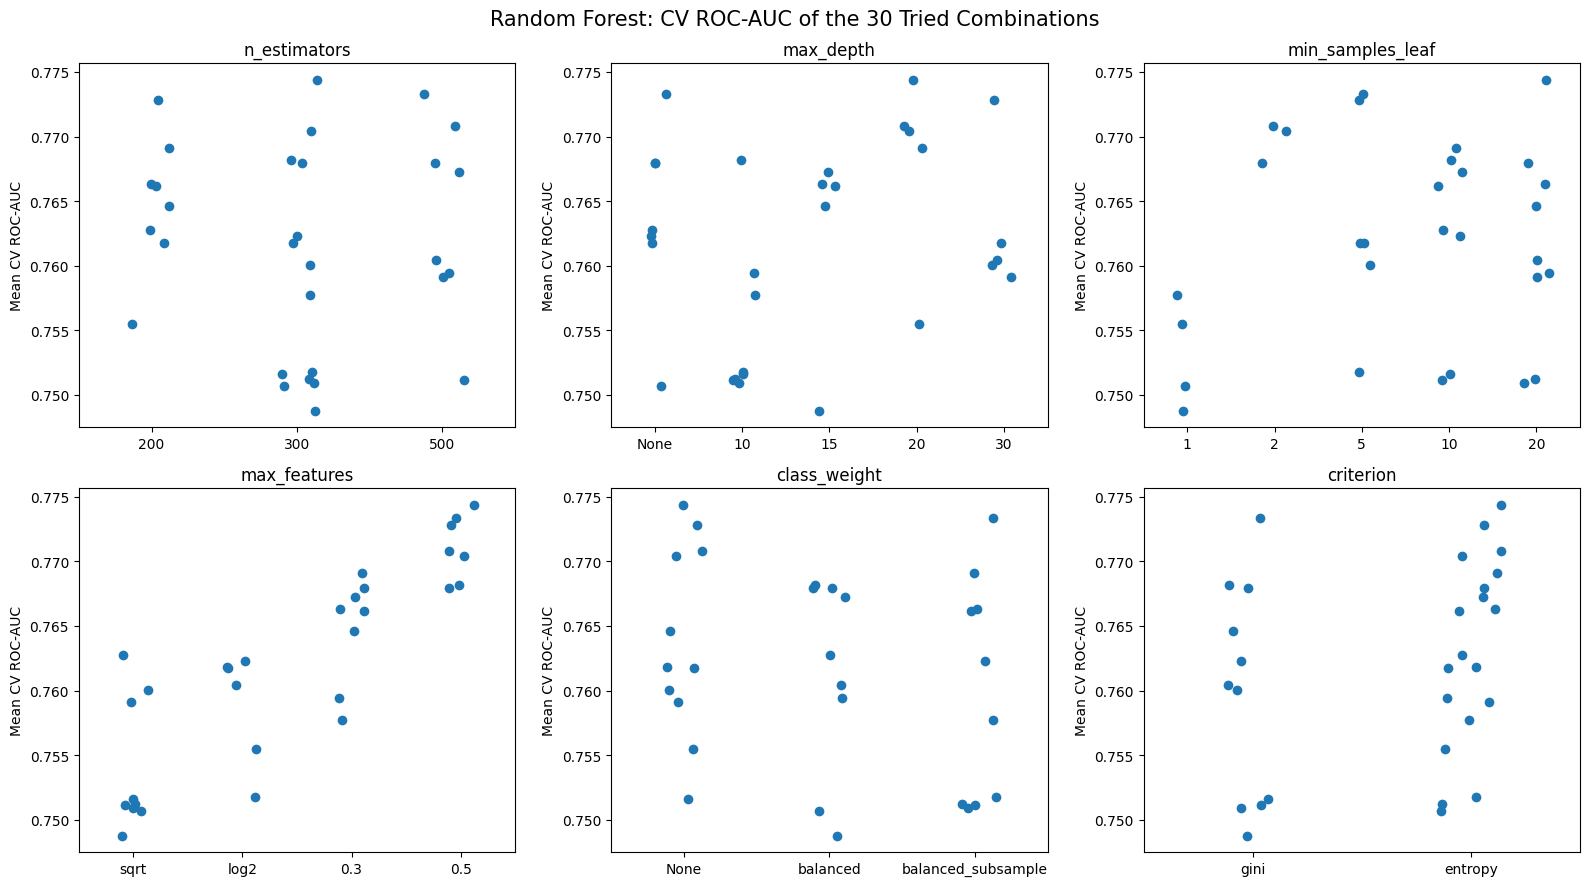

In [12]:
# Mean CV ROC-AUC of all 30 combinations, grouped by the value of each hyperparameter
# (each dot is one combination: x = the value it used, y = its mean CV ROC-AUC)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))   # 2 rows x 3 columns = 6 small plots

# axes.ravel() turns the 2x3 grid into a simple list so we can loop over it
for ax, param in zip(axes.ravel(), param_distributions):
    # astype(str) so numbers and text (like 0.5 and "sqrt") can share one axis,
    # order keeps the values in the same order as in param_distributions,
    # jitter moves the dots a little to the sides so they don't hide each other
    sns.stripplot(x=tuning_results[f"param_{param}"].astype(str),
                  y=tuning_results["mean_test_roc_auc"],
                  order=[str(v) for v in param_distributions[param]],
                  size=7, jitter=0.15, ax=ax)
    ax.set_title(param)
    ax.set_xlabel("")
    ax.set_ylabel("Mean CV ROC-AUC")

plt.suptitle("Random Forest: CV ROC-AUC of the 30 Tried Combinations", fontsize=15)
plt.tight_layout()   # stops the titles and labels from overlapping
# save before plt.show(), because after show() the figure is cleared
plt.savefig(f"{PLOTS_DIR}/model1_tuning_results.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: Hyperparameter Tuning Results

The best combination was **300 trees, `max_depth` = 20, `min_samples_leaf` = 20, `max_features` = 0.5, `criterion` = entropy, and no class weights**, with a mean CV ROC-AUC of **0.7744 ± 0.0075**. The second-best combination (0.7733) used different settings (500 trees, no depth limit, balanced_subsample weights). The difference between the two is smaller than one standard deviation, so several combinations perform almost equally well.

What the plots show:
- **`max_features` had the strongest effect.** All combinations with 0.5 (about 11 of the 23 features at each split) are at the top, followed by 0.3, while `sqrt` and `log2` (about 4 features) gave the lowest scores. A likely reason is that `booking_origin` is much more informative than the other features. When each split can only choose from 4 random features, it is often not available, and many splits have to use weaker features.
- **`min_samples_leaf` = 1 gave some of the lowest scores.** Leaves with a single row produce noisy probabilities, while larger leaves average more bookings and overfit less.
- **`n_estimators`, `max_depth`, `criterion` and `class_weight` show no clear pattern** within the tried values. Gini and entropy gave similar results, which is expected since both measure impurity in a similar way.
- **Class weights had little effect on ROC-AUC but a large effect on F1 at the 0.5 threshold.** In the top 10 table, the weighted combinations have a CV F1 of about 0.27 to 0.42 (most of them around 0.39 to 0.42), compared with 0.09 to 0.15 without weights. Weighting shifts the predicted probabilities upwards, which changes how many bookings pass the 0.5 threshold, but it has little effect on how well the model ranks the bookings. Since we choose the threshold separately in Section 2.4, ROC-AUC is the more suitable criterion for selecting the hyperparameters.

In [13]:
# position of the best combination inside tuning_results
best_idx = search.best_index_

# same kind of table as default_summary, but for the tuned model
# (these numbers come from the search, so nothing has to be trained again)
tuned_summary = pd.DataFrame({
    "train_mean": [tuning_results.loc[best_idx, f"mean_train_{m}"] for m in METRICS],
    "cv_mean": [tuning_results.loc[best_idx, f"mean_test_{m}"] for m in METRICS],
    "cv_std": [tuning_results.loc[best_idx, f"std_test_{m}"] for m in METRICS],
}, index=METRICS)

# Default vs. tuned model, both with the 0.5 threshold
# (concat with a dictionary puts the two tables side by side under two headings)
pd.concat({"Default Random Forest": default_summary,
           "Tuned Random Forest": tuned_summary}, axis=1).round(4)

Default Random Forest                 Tuned Random Forest          \
                     train_mean cv_mean  cv_std          train_mean cv_mean   
accuracy                 0.9998  0.8505  0.0050              0.8603  0.8523   
precision                0.9995  0.4982  0.0240              0.8304  0.5716   
recall                   0.9992  0.0806  0.0040              0.0811  0.0471   
f1                       0.9994  0.1387  0.0055              0.1477  0.0870   
roc_auc                  1.0000  0.7422  0.0067              0.8794  0.7744   

                   
           cv_std  
accuracy   0.0056  
precision  0.0414  
recall     0.0042  
f1         0.0068  
roc_auc    0.0075

### Interpretation: Default vs. Tuned Model

Tuning improved the CV ROC-AUC from **0.742 to 0.7744** and greatly reduced overfitting: the gap between training and validation ROC-AUC dropped from 1.000 vs. 0.742 to 0.879 vs. 0.774. With a depth limit and at least 20 bookings per leaf, the tuned trees can no longer memorise individual rows. Its variation across the folds is similar to that of the default model (standard deviation 0.0075 vs. 0.0067).

However, at the 0.5 threshold, the tuned model's recall (4.7%) and F1-score (0.087) are even lower than those of the default model. Because each leaf averages at least 20 bookings and no class weights are used, the predicted probabilities of completed bookings rarely exceed 0.5. This is a threshold problem, not a ranking problem, since ROC-AUC improved. It is addressed in the next section.

### 2.4 Choosing the Decision Threshold

The model outputs a probability, and a booking is predicted as completed when this probability is at least the threshold. The default threshold of 0.5 is not necessarily suitable when only 15% of bookings are completed, so we choose the threshold that gives the **highest F1-score**, which balances precision and recall for the completed class.

The threshold must be chosen without looking at the test set. We use **out-of-fold predictions** on the training set: with the same five folds, each training row is predicted by a model that was trained on the other four folds and has never seen that row.

In [14]:
# Out-of-fold probabilities with the best hyperparameters and the same folds.
# cross_val_predict trains 5 models (one per fold), and every training row is predicted
# by the model that did NOT see it during training, so the probabilities are honest.
# clone(best_rf) = untrained copy with the best settings, [:, 1] = probability of class 1
oof_proba = cross_val_predict(clone(best_rf), X_train, y_train, groups=groups,
                              cv=cv, method="predict_proba")[:, 1]

# thresholds to try: 0.05, 0.06, ..., 0.95 (rounded so we don't get values like 0.15000000002)
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
# for each threshold: oof_proba >= t turns the probabilities into True/False predictions,
# then we calculate precision, recall and F1 for the completed class
threshold_scores = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_train, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
    "f1": [f1_score(y_train, oof_proba >= t, zero_division=0) for t in thresholds],
})

# keep the threshold with the highest F1 (idxmax gives the row of the largest value)
best_threshold = float(threshold_scores.loc[threshold_scores["f1"].idxmax(), "threshold"])
print(f"Threshold with the highest out-of-fold F1: {best_threshold:.2f}")
# only show a few thresholds so the table stays short
threshold_scores[threshold_scores["threshold"].isin(
    [0.1, 0.15, 0.2, best_threshold, 0.25, 0.3, 0.4, 0.5])].round(4)

Threshold with the highest out-of-fold F1: 0.19


,threshold,precision,recall,f1
5,0.10,0.2380,0.8660,0.3734
10,0.15,0.2827,0.7637,0.4127
14,0.19,0.3153,0.6640,0.4275
15,0.20,0.3209,0.6334,0.4260
20,0.25,0.3600,0.4962,0.4173
25,0.30,0.3957,0.3633,0.3788
35,0.40,0.4647,0.1532,0.2305
45,0.50,0.5654,0.0471,0.0869


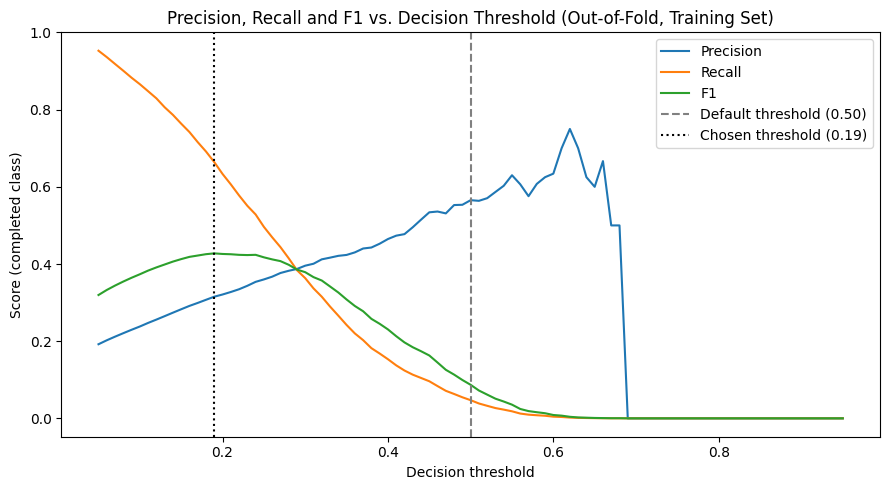

In [15]:
# how precision, recall and F1 change when we move the threshold
plt.figure(figsize=(9, 5))
for metric in ["precision", "recall", "f1"]:
    plt.plot(threshold_scores["threshold"], threshold_scores[metric], label=metric.capitalize())

# vertical lines that mark the default threshold and the one we chose
plt.axvline(0.5, color="grey", linestyle="--", label="Default threshold (0.50)")
plt.axvline(best_threshold, color="black", linestyle=":",
            label=f"Chosen threshold ({best_threshold:.2f})")

plt.title("Precision, Recall and F1 vs. Decision Threshold (Out-of-Fold, Training Set)")
plt.xlabel("Decision threshold")
plt.ylabel("Score (completed class)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/model1_threshold_selection.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: Threshold Selection

The highest out-of-fold F1-score (0.428) is reached at a threshold of **0.19**. Compared with the default threshold of 0.5, recall for completed bookings increases from **4.7% to 66.4%**, while precision decreases from 56.5% to 31.5%.

The plot shows the trade-off clearly: lowering the threshold finds more completed bookings (higher recall), but more incomplete bookings are wrongly flagged (lower precision). The F1 curve is quite flat around its peak (about 0.41 to 0.43 for thresholds between 0.15 and 0.25), so the result does not depend strongly on the exact threshold value. Above about 0.69, precision drops to 0 because the model never gives a probability that high, so no booking is predicted as completed.

From a business perspective, the threshold is a decision for the CCO: a lower threshold suits a wide re-engagement campaign, while a higher threshold suits a smaller, more targeted action. We use 0.19 because it gives the best balance between precision and recall.

In [16]:
# Cross-validation metrics per fold at both thresholds, from the out-of-fold predictions.
# cv.split returns the same folds as before because random_state is fixed.
fold_rows = []
for fold, (_, val_idx) in enumerate(cv.split(X_train, y_train, groups), start=1):   # _ = training rows, not needed here
    y_val = y_train.iloc[val_idx]   # true labels of this fold
    p_val = oof_proba[val_idx]      # out-of-fold probabilities of this fold
    # score the fold twice: with the default 0.5 and with the chosen threshold
    for threshold_type, t in [("default", 0.5), ("tuned", best_threshold)]:
        scores = compute_metrics(y_val, (p_val >= t).astype(int), p_val)
        # **scores adds the 5 metric values to the row as extra columns
        fold_rows.append({"fold": fold, "threshold_type": threshold_type, "threshold": t, **scores})

# one row per fold and threshold (5 folds x 2 thresholds = 10 rows)
cv_folds = pd.DataFrame(fold_rows)

# ddof=0 so the standard deviation is calculated the same way as in scikit-learn's cv_results_
grouped = cv_folds.groupby("threshold_type")[METRICS]
# mean and std over the 5 folds for every metric
cv_by_threshold = pd.concat({"mean": grouped.mean(), "std": grouped.std(ddof=0)}, axis=1)
# reorder the columns to (metric, mean/std), in the same order as METRICS
cv_by_threshold = cv_by_threshold.swaplevel(axis=1).reindex(columns=METRICS, level=0)
cv_by_threshold.round(4)

accuracy         precision          recall              f1  \
                   mean     std      mean     std    mean     std    mean   
threshold_type                                                              
default          0.8523  0.0056    0.5716  0.0414  0.0471  0.0042  0.0870   
tuned            0.7345  0.0029    0.3153  0.0087  0.6644  0.0173  0.4275   

                       roc_auc          
                   std    mean     std  
threshold_type                          
default         0.0068  0.7744  0.0075  
tuned           0.0086  0.7744  0.0075

Because the threshold was chosen using these same out-of-fold predictions, the cross-validation scores at the tuned threshold are slightly optimistic. The test set results in the next section give an unbiased estimate.

### 2.5 Evaluation Metrics & Visualizations (Test Set)

The tuned model was already retrained on the whole training set by `RandomizedSearchCV` (`refit="roc_auc"`). We now evaluate it **once** on the test set, at both the default and the chosen threshold.

In [17]:
fit_time = search.refit_time_   # seconds to train the final model on the full training set

# predict the test set (only once) and time it
start = time.perf_counter()
test_proba = best_rf.predict_proba(X_test)[:, 1]   # probability of "completed" for every test booking
predict_time = time.perf_counter() - start

# turn the probabilities into 0/1 labels with each threshold
# (>= gives True/False, astype(int) turns it into 1/0)
test_pred_default = (test_proba >= 0.5).astype(int)
test_pred_tuned = (test_proba >= best_threshold).astype(int)

# the same 5 metrics for both thresholds
test_metrics_default = compute_metrics(y_test, test_pred_default, test_proba)
test_metrics_tuned = compute_metrics(y_test, test_pred_tuned, test_proba)

# both thresholds next to the baseline in one table
pd.DataFrame({
    "Random Forest, threshold 0.50": test_metrics_default,
    f"Random Forest, threshold {best_threshold:.2f}": test_metrics_tuned,
    "Majority-class baseline": baseline_metrics,
}).round(4)

,"Random Forest, threshold 0.50","Random Forest, threshold 0.19",Majority-class baseline
accuracy,0.8523,0.7383,0.8495
precision,0.6148,0.3237,0.0000
recall,0.0498,0.6782,0.0000
f1,0.0921,0.4383,0.0000
roc_auc,0.7816,0.7816,0.5000


In [18]:
# names used in the reports and plots instead of 0 and 1
class_names = ["Incomplete (0)", "Completed (1)"]

# classification_report gives precision, recall and F1 for EACH class separately,
# plus the macro average (simple average of both classes) and the weighted average
# digits=3 -> 3 decimal places
print(f"Classification report - threshold {best_threshold:.2f}\n")
print(classification_report(y_test, test_pred_tuned, target_names=class_names, digits=3))

print("Classification report - threshold 0.50\n")
print(classification_report(y_test, test_pred_default, target_names=class_names, digits=3))

Classification report - threshold 0.19

                precision    recall  f1-score   support

Incomplete (0)      0.929     0.749     0.829      8504
 Completed (1)      0.324     0.678     0.438      1507

      accuracy                          0.738     10011
     macro avg      0.626     0.714     0.634     10011
  weighted avg      0.838     0.738     0.771     10011

Classification report - threshold 0.50

                precision    recall  f1-score   support

Incomplete (0)      0.855     0.994     0.920      8504
 Completed (1)      0.615     0.050     0.092      1507

      accuracy                          0.852     10011
     macro avg      0.735     0.522     0.506     10011
  weighted avg      0.819     0.852     0.795     10011



### Interpretation: Test Set Results

The test results are very close to the cross-validation results (for example, ROC-AUC 0.782 on the test set vs. 0.774 in CV, and F1 0.438 vs. 0.428 at the 0.19 threshold). This shows that the model generalises to unseen bookings in a stable way.

- **At the chosen threshold (0.19)**, the model finds **67.8%** of the completed bookings (recall), and **32.4%** of the bookings it predicts as completed are actually completed (precision), giving an F1-score of **0.438**. This precision is more than twice the 15% completion rate, so the model's predictions are much better than random selection.
- **At the default threshold (0.5)**, accuracy (0.852) is barely above the baseline (0.8495), and the model finds only 5.0% of the completed bookings.
- Accuracy is lower at 0.19 (0.738) because more incomplete bookings are flagged as completed. This is the expected trade-off of favouring recall for the minority class, and it shows again why accuracy is misleading here.

Per class, the model is much stronger on incomplete bookings (precision 0.929, recall 0.749, F1 0.829) than on completed bookings (precision 0.324, recall 0.678, F1 0.438). The macro-average F1-score improves from 0.506 at 0.5 to **0.634** at 0.19.

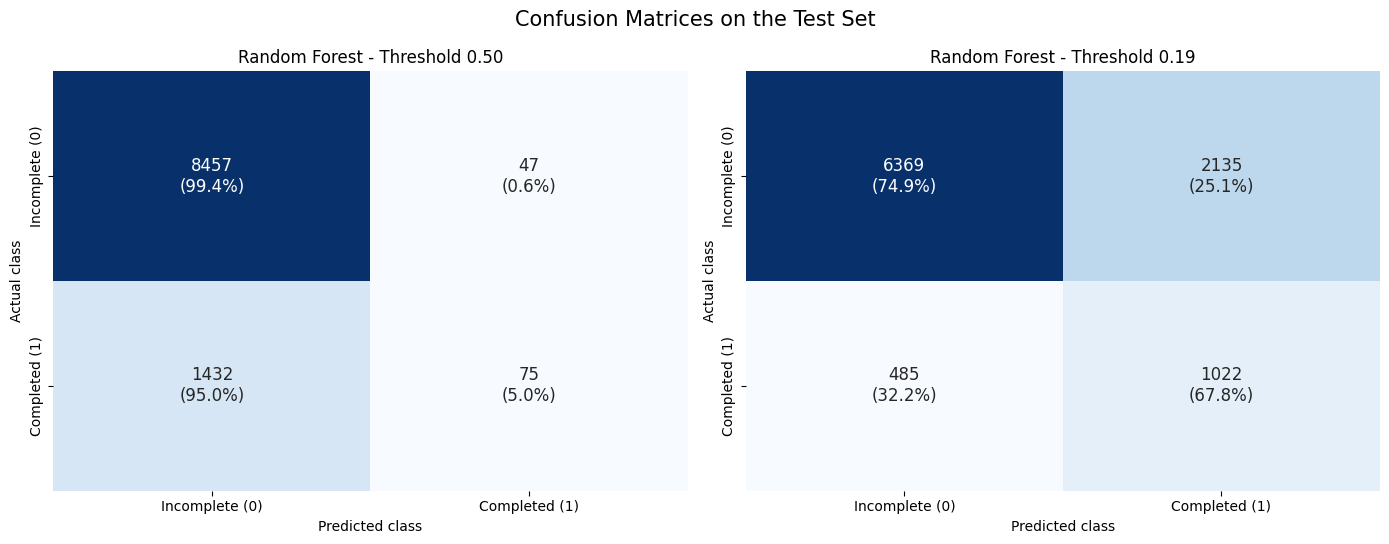

In [19]:
# two confusion matrices side by side, one for each threshold
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (title, preds) in zip(axes, [("Threshold 0.50", test_pred_default),
                                     (f"Threshold {best_threshold:.2f}", test_pred_tuned)]):
    # rows = actual class, columns = predicted class
    cm = confusion_matrix(y_test, preds)
    # Each cell shows the count and its share of the actual class (row)
    # keepdims=True keeps the row totals as a column so every row is divided by its own total
    row_share = cm / cm.sum(axis=1, keepdims=True)
    # text inside each cell: the count on the first line and the percentage below it
    labels = np.array([[f"{cm[i, j]}\n({row_share[i, j]:.1%})" for j in range(2)]
                       for i in range(2)])
    # fmt="" because our labels are already text, cbar=False hides the colour bar
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 12}, ax=ax)
    ax.set_title(f"Random Forest - {title}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.suptitle("Confusion Matrices on the Test Set", fontsize=15)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/model1_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: Confusion Matrices

- **Threshold 0.50:** the model correctly identifies 8,457 incomplete bookings but only **75 of the 1,507 completed bookings**. The other 1,432 completed bookings (95.0%) are missed (false negatives). It rarely predicts "completed", so it makes only 47 false positives.
- **Threshold 0.19:** the model identifies **1,022 completed bookings (67.8%)** and misses 485 (32.2%). In exchange, 2,135 incomplete bookings (25.1%) are wrongly predicted as completed (false positives), while 6,369 (74.9%) are still correctly identified.

At the chosen threshold, the main error type is false positives: for every completed booking found, about 2.1 incomplete bookings are also flagged. For the CCO, this means that a group of bookings flagged by the model will contain about 32% completed bookings, compared with 15% in the full dataset. The predictions for every test booking are saved with their original row IDs so that the misclassified bookings can be analysed in the model comparison section.

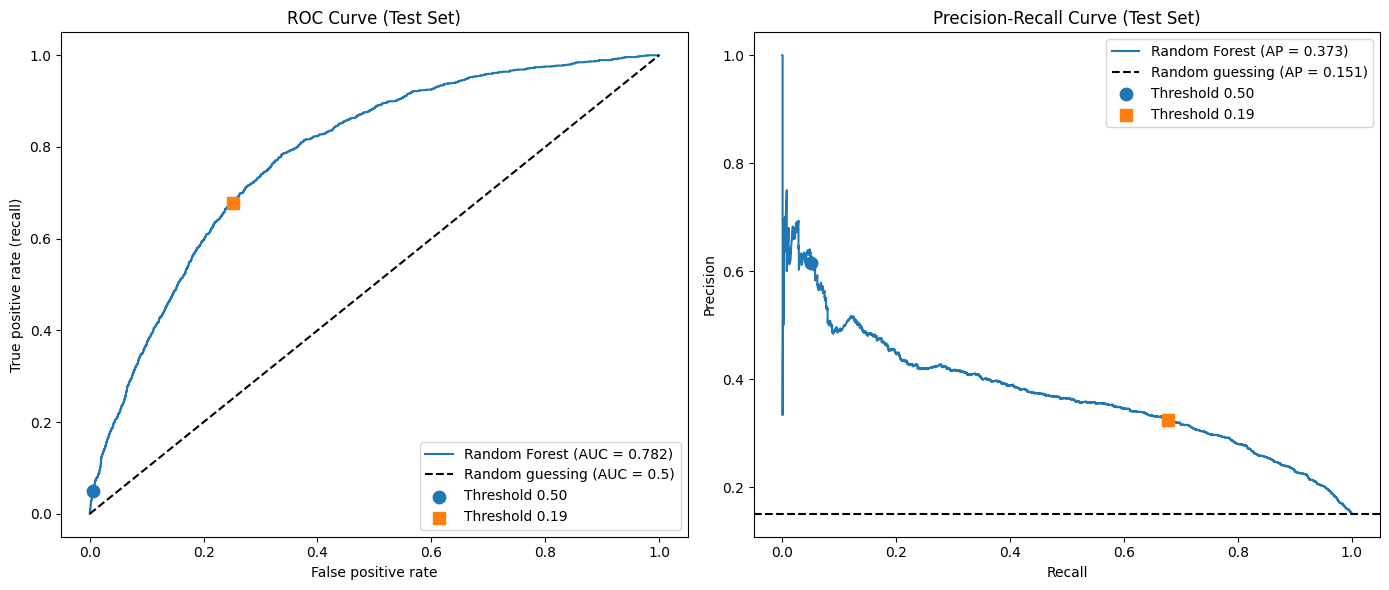

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC curve, with the two thresholds marked on it
# roc_curve tries every possible threshold and gives the false positive rate (fpr)
# and the true positive rate (tpr) for each one
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[0].plot(fpr, tpr, label=f"Random Forest (AUC = {test_metrics_tuned['roc_auc']:.3f})")
# the diagonal line is what random guessing would give
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")

# mark where our two thresholds are on the curve
for t, marker in [(0.5, "o"), (best_threshold, "s")]:
    # ravel() gives the 4 cells of the confusion matrix in the order tn, fp, fn, tp
    tn, fp, fn, tp = confusion_matrix(y_test, (test_proba >= t).astype(int)).ravel()
    # FPR = fp / all actual negatives, TPR (= recall) = tp / all actual positives
    axes[0].scatter(fp / (fp + tn), tp / (tp + fn), marker=marker, s=80, zorder=3,
                    label=f"Threshold {t:.2f}")

axes[0].set_title("ROC Curve (Test Set)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(loc="lower right")

# Precision-recall curve: more informative than ROC when the positive class is rare
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_proba)
# average precision (AP) summarises the whole precision-recall curve in one number
avg_precision = average_precision_score(y_test, test_proba)
axes[1].plot(recall_curve, precision_curve, label=f"Random Forest (AP = {avg_precision:.3f})")
# random guessing gives a precision equal to the share of completed bookings (about 15%)
axes[1].axhline(y_test.mean(), color="black", linestyle="--",
                label=f"Random guessing (AP = {y_test.mean():.3f})")

# mark the two thresholds on this curve too
for t, marker in [(0.5, "o"), (best_threshold, "s")]:
    preds = (test_proba >= t).astype(int)
    axes[1].scatter(recall_score(y_test, preds), precision_score(y_test, preds),
                    marker=marker, s=80, zorder=3, label=f"Threshold {t:.2f}")

axes[1].set_title("Precision-Recall Curve (Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/model1_roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: ROC and Precision-Recall Curves

The ROC curve is clearly above the diagonal, with an **AUC of 0.782**. This means that a randomly chosen completed booking receives a higher predicted probability than a randomly chosen incomplete booking about 78% of the time. The curve is still far from the top-left corner, so the classes are only moderately separable. This is consistent with the EDA, where no single feature showed a strong relationship with booking completion.

The markers show the two thresholds. The 0.5 threshold sits near the bottom-left of the ROC curve (very few bookings predicted as completed), while the 0.19 threshold reaches a recall of about 0.68 at a false positive rate of about 0.25.

The precision-recall curve focuses on the completed class, which makes it more informative for imbalanced data. The average precision (AP) is **0.373**, compared with 0.151 for random guessing, which is about 2.5 times better. Precision is around 0.6 only for the small group of bookings with the highest predicted probabilities, and it drops quickly as recall increases. In other words, the model is confident about only a small share of the completed bookings.

#### Overfitting check

A Random Forest always scores higher on the rows it was trained on, so some gap is expected. What matters is that the cross-validation and test scores are close to each other, which shows that the model generalises in a stable way.

In [21]:
# predict the training rows (rows the model has already seen) to compare with CV and test
train_proba = best_rf.predict_proba(X_train)[:, 1]

# a large gap between the training score and the CV/test scores means overfitting
pd.Series({
    "Training set (rows the model has seen)": roc_auc_score(y_train, train_proba),
    "Cross-validation (mean of 5 folds)": tuning_results.loc[best_idx, "mean_test_roc_auc"],
    "Test set": test_metrics_tuned["roc_auc"],
}, name="ROC-AUC").round(4)

,ROC-AUC
Training set (rows the model has seen),0.8796
Cross-validation (mean of 5 folds),0.7744
Test set,0.7816


### Interpretation: Overfitting Check

The training ROC-AUC (0.880) is higher than the cross-validation (0.774) and test (0.782) values, which is normal for a Random Forest. The gap is much smaller than for the default model (1.000 vs. 0.742), so the tuned depth and leaf-size limits successfully reduced overfitting.

More importantly, the cross-validation and test scores differ by less than 0.01. This means that the cross-validation estimate is reliable, and that the group-aware split did not make the test set easier or harder than the training data.

#### Feature Importance

We report two kinds of feature importance:
- **Impurity-based importance** (`feature_importances_`): how much each feature reduced impurity, summed over all splits in all trees. It is calculated on the training data and tends to favour features with many distinct values.
- **Permutation importance**: how much the test ROC-AUC drops when the values of one feature are randomly shuffled. A large drop means that the model really depends on that feature. This is calculated on the test set and repeated 10 times per feature.

In [22]:
# impurity importance: built into the forest and calculated from the training data
impurity_importance = pd.Series(best_rf.feature_importances_, index=X_train.columns)

# permutation importance: shuffle one test column at a time and measure how much ROC-AUC drops
# n_repeats=10 -> every column is shuffled 10 times and the drops are averaged
perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE)

# both kinds of importance in one table, sorted from the most to the least important
feature_importance = pd.DataFrame({
    "impurity_importance": impurity_importance,
    "permutation_importance_mean": perm.importances_mean,
    "permutation_importance_std": perm.importances_std,
}, index=X_train.columns).sort_values("permutation_importance_mean", ascending=False)

feature_importance.round(4)

,impurity_importance,permutation_importance_mean,permutation_importance_std
booking_origin,0.3126,0.1885,0.0102
route,0.1562,0.0299,0.0025
flight_duration,0.0770,0.0263,0.0025
length_of_stay,0.1073,0.0229,0.0022
total_extra_services,0.0318,0.0056,0.0011
purchase_lead,0.1258,0.0038,0.0012
sales_channel_Mobile,0.0095,0.0019,0.0007
sales_channel_Internet,0.0096,0.0017,0.0007
wants_preferred_seat,0.0112,0.0015,0.0008
flight_hour,0.0729,0.0012,0.0005


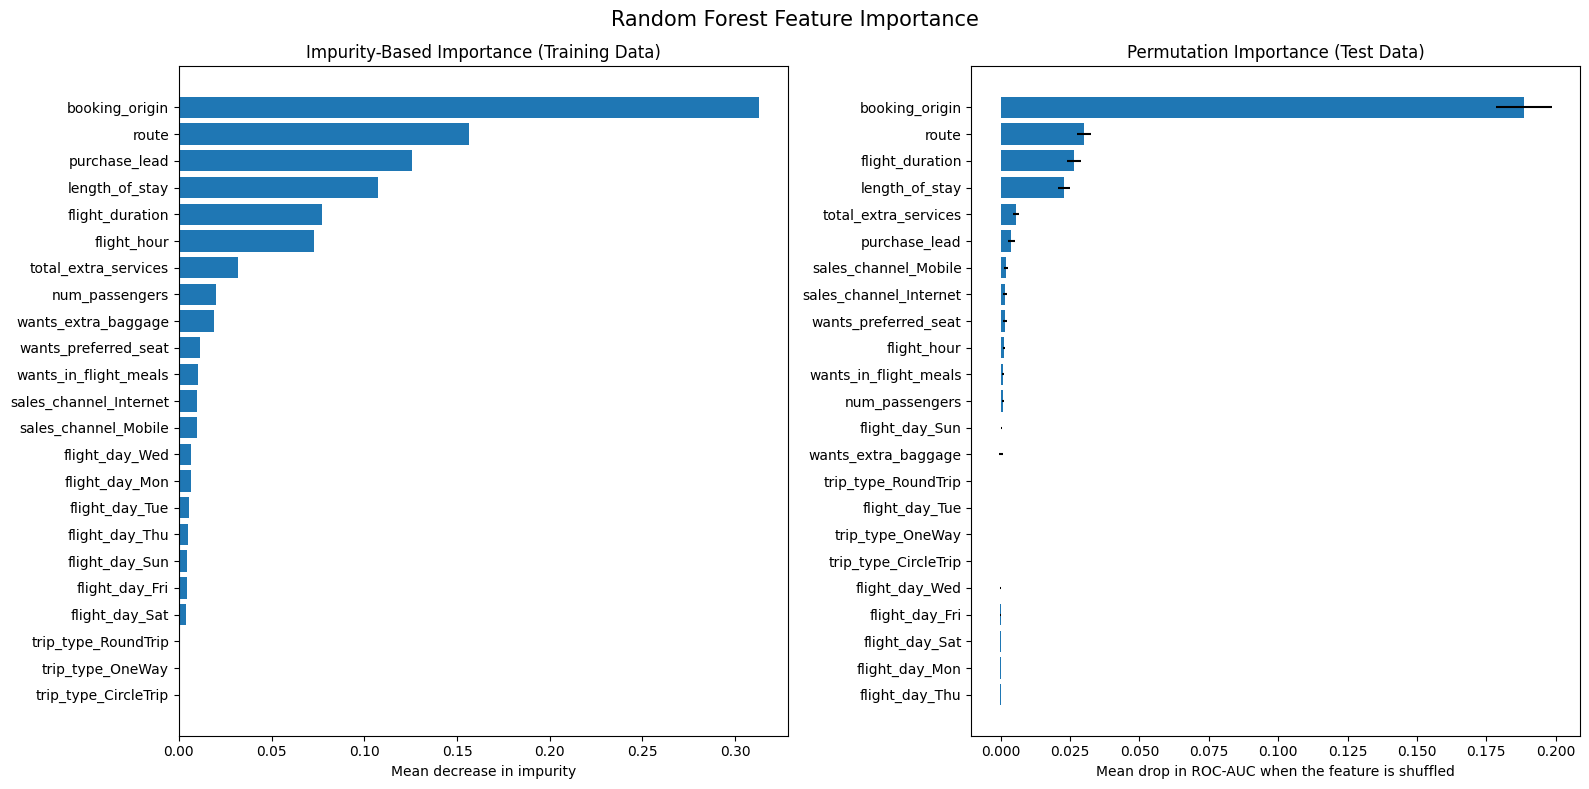

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# left: impurity importance, sorted from small to large so the biggest bar ends up at the top
impurity_sorted = feature_importance["impurity_importance"].sort_values()
axes[0].barh(impurity_sorted.index, impurity_sorted.values)   # barh = horizontal bars
axes[0].set_title("Impurity-Based Importance (Training Data)")
axes[0].set_xlabel("Mean decrease in impurity")

# right: permutation importance, xerr draws the std of the 10 repeats as small error bars
perm_sorted = feature_importance.sort_values("permutation_importance_mean")
axes[1].barh(perm_sorted.index, perm_sorted["permutation_importance_mean"],
             xerr=perm_sorted["permutation_importance_std"])
axes[1].set_title("Permutation Importance (Test Data)")
axes[1].set_xlabel("Mean drop in ROC-AUC when the feature is shuffled")

plt.suptitle("Random Forest Feature Importance", fontsize=15)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/model1_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation: Feature Importance

- **`booking_origin` is by far the most important feature** in both measures. Shuffling it lowers the test ROC-AUC by about 0.19, from 0.78 to about 0.59. In the raw data, completion rates differ strongly between booking origins (for example, about 34% for Malaysia compared with about 5% for Australia, the largest market).
- **`route`, `flight_duration` and `length_of_stay`** follow, each lowering ROC-AUC by about 0.02 to 0.03 when shuffled. `flight_duration` matches the EDA finding that completed bookings tend to have shorter flights. `length_of_stay` is also lower for completed bookings (median of 6 days vs. 17 days in the raw data).
- **`purchase_lead` and `flight_hour` rank highly on impurity importance (0.126 and 0.073) but have almost no permutation importance (0.004 and 0.001).** This is the bias of impurity-based importance described above. Features with many distinct values offer many possible split points, so the trees use them often, but these splits mostly fit noise in the training data and do not help on new bookings.
- **The service preferences** have small individual effects. `total_extra_services` is the most useful of them (0.006), and it shares its importance with the three flags it was created from.
- **`flight_day` and `trip_type` have almost no effect** (values close to 0, and slightly negative values are only random noise). The day of the flight does not help to predict completion, and almost all bookings (99%) are round trips, so `trip_type` rarely separates the bookings.

For the CCO, these results suggest that where a booking comes from and which route it is for are the strongest signals of completion. These are associations learned by the model, not causes. Frequency encoding also gives some countries and routes the same value, so the model cannot fully separate them.

#### Computational Cost

In [24]:
# running times that we measured earlier, used for the computational cost comparison
# (dtype=object so the number of trees is shown as 300 and not 300.0)
pd.Series({
    "Hyperparameter search, 30 combinations x 5 folds (seconds)": round(tuning_time, 1),
    "Training the final model on 39,989 rows (seconds)": round(fit_time, 2),
    "Predicting 10,011 test bookings (seconds)": round(predict_time, 3),
    "Number of trees in the final model": best_rf.n_estimators,
}, name="Random Forest", dtype=object)

,Random Forest
"Hyperparameter search, 30 combinations x 5 folds (seconds)",2171.3
"Training the final model on 39,989 rows (seconds)",17.4
"Predicting 10,011 test bookings (seconds)",0.29
Number of trees in the final model,300


### Interpretation: Computational Cost

Hyperparameter tuning was the most expensive step, taking about 36 minutes for 150 model fits on a free Google Colab session, which has only 2 CPU cores. Once tuned, the final model trains in about 17 seconds and predicts all 10,011 test bookings in about 0.3 seconds, which is fast enough for real-time predictions in the Phase 2 dashboard. The main costs compared with a simpler model are the tuning time and the memory needed to store 300 trees. These times depend on the computer that runs the notebook.

### 2.6 Saving the Results

All Model 1 outputs are saved so that the models can be compared later without retraining:

| File | Content |
| --- | --- |
| `evaluation_results/model1_metrics.csv` | Every metric: CV mean and std and test value, at both thresholds |
| `evaluation_results/model1_predictions.csv` | One row per test booking: original row ID, true class, predicted probability, predicted class at both thresholds |
| `evaluation_results/model1_cv_folds.csv` | Metrics of each of the 5 folds at both thresholds |
| `evaluation_results/model1_tuning_results.csv` | All 30 hyperparameter combinations with their CV and training scores and fit times |
| `evaluation_results/model1_feature_importance.csv` | Impurity and permutation importance of every feature |
| `evaluation_results/model1_run_info.json` | Best hyperparameters, chosen threshold, run times and setup details |
| `plots/model1_*.png` | All figures in this section |

In [25]:
# save everything so the model comparison can be done without training the model again

# 1) Metrics summary: one row per metric with the CV and test values at both thresholds
metrics_rows = []
for m in METRICS:
    metrics_rows.append({
        "model": "Random Forest",
        "metric": m,
        "cv_mean_default_threshold": cv_by_threshold.loc["default", (m, "mean")],
        "cv_std_default_threshold": cv_by_threshold.loc["default", (m, "std")],
        "cv_mean_tuned_threshold": cv_by_threshold.loc["tuned", (m, "mean")],
        "cv_std_tuned_threshold": cv_by_threshold.loc["tuned", (m, "std")],
        "test_default_threshold": test_metrics_default[m],
        "test_tuned_threshold": test_metrics_tuned[m],
    })
# index=False -> don't write the pandas row numbers as an extra column
pd.DataFrame(metrics_rows).to_csv(f"{RESULTS_DIR}/model1_metrics.csv", index=False)

# 2) Test predictions, with the original row number so both models can be matched
pd.DataFrame({
    "row_id": test_row_ids,
    "y_true": y_test.values,
    "y_proba": test_proba,
    "y_pred_default_threshold": test_pred_default,
    "y_pred_tuned_threshold": test_pred_tuned,
}).to_csv(f"{RESULTS_DIR}/model1_predictions.csv", index=False)

# 3) Per-fold CV metrics
cv_folds.to_csv(f"{RESULTS_DIR}/model1_cv_folds.csv", index=False)

# 4) All tuning results (the "params" column is dropped because the param_ columns hold the same values)
score_cols = [c for c in tuning_results.columns
              if c.startswith(("mean_test_", "std_test_", "mean_train_", "rank_test_"))]
tuning_results[param_cols + score_cols + ["mean_fit_time"]].to_csv(
    f"{RESULTS_DIR}/model1_tuning_results.csv", index=False)

# 5) Feature importance (the feature names are the index, saved in a column called "feature")
feature_importance.to_csv(f"{RESULTS_DIR}/model1_feature_importance.csv", index_label="feature")

# 6) Settings and run times
run_info = {
    "model": "RandomForestClassifier",
    "best_params": search.best_params_,
    "default_threshold": 0.5,
    "tuned_threshold": best_threshold,
    "threshold_rule": "maximum out-of-fold F1 on the training set",
    "tuning_metric": "roc_auc",
    "cv": "StratifiedGroupKFold, 5 folds, groups = identical feature rows",
    "random_state": RANDOM_STATE,
    "n_iter_random_search": search.n_iter,
    "tuning_time_seconds": tuning_time,
    "final_fit_time_seconds": fit_time,
    "test_predict_time_seconds": predict_time,
    "n_train_rows": len(X_train),
    "n_test_rows": len(X_test),
    "positive_class": 1,
    "sklearn_version": sklearn.__version__,
}
# indent=2 makes the file easy to read, default=str turns anything json can't save into text
with open(f"{RESULTS_DIR}/model1_run_info.json", "w") as f:
    json.dump(run_info, f, indent=2, default=str)

# list the saved files to check that everything was written
print("Saved files:")
for folder in [RESULTS_DIR, PLOTS_DIR]:
    for name in sorted(os.listdir(folder)):
        if name.startswith("model1_"):
            print(f"  {folder}/{name}")

Saved files:
  evaluation_results/model1_cv_folds.csv
  evaluation_results/model1_feature_importance.csv
  evaluation_results/model1_metrics.csv
  evaluation_results/model1_predictions.csv
  evaluation_results/model1_run_info.json
  evaluation_results/model1_tuning_results.csv
  plots/model1_confusion_matrix.png
  plots/model1_feature_importance.png
  plots/model1_roc_pr_curves.png
  plots/model1_threshold_selection.png
  plots/model1_tuning_results.png


### 2.7 Summary of Model 1 (Random Forest)

| Item | Result |
| --- | --- |
| Best hyperparameters | 300 trees, max_depth 20, min_samples_leaf 20, max_features 0.5, entropy, no class weights |
| CV ROC-AUC (5 grouped folds) | 0.7744 ± 0.0075 |
| Test ROC-AUC | 0.782 |
| Chosen threshold | 0.19 (maximum out-of-fold F1) |
| Test results at 0.19 (completed class) | Precision 0.324, Recall 0.678, F1 0.438 |
| Test accuracy at 0.19 | 0.738 (baseline: 0.8495) |
| Most important features | booking_origin, then route, flight_duration and length_of_stay |
| Training time / prediction time | about 17 s / about 0.3 s for 10,011 bookings (Google Colab) |

**Main findings**
- The Random Forest ranks bookings clearly better than chance (ROC-AUC 0.78, average precision 0.37 vs. 0.15), and its cross-validation and test results agree, so the performance estimate is reliable.
- Hyperparameter tuning mainly reduced overfitting. Considering more features at each split (`max_features` = 0.5) and limiting leaf size had the largest positive effect.
- Because of the class imbalance, the default threshold of 0.5 almost never predicts a completed booking. Lowering the threshold to 0.19 raises recall from 5% to about 68%, at the cost of more false positives.
- The booking origin dominates the predictions. Calendar features (`flight_day`, `flight_hour`) contribute almost nothing.

**Limitations**
- Completed bookings are only moderately separable from incomplete ones: about 32% of them are still missed, and about two out of three bookings flagged as completed are incomplete.
- The model is less transparent than a single decision tree: it explains which features matter, but not exact decision rules.
- Frequency encoding of `route` and `booking_origin` merges some categories that have the same frequency, which may limit performance.

All results are saved in `evaluation_results/` and `plots/` for the model comparison.